In [1]:
import gluonts
from gluonts.dataset.repository import get_dataset, dataset_recipes
from gluonts.dataset.multivariate_grouper import MultivariateGrouper
from gluonts.dataset.repository.datasets import dataset_recipes, get_dataset
from gluonts.evaluation.backtest import make_evaluation_predictions
from gluonts.evaluation import MultivariateEvaluator
from matplotlib import pyplot as plt
import matplotlib.dates as mdates
from typing import List, Optional, Callable, Iterable
from itertools import islice
import pandas as pd
import numpy as np

In [2]:
print(f"Available datasets: {list(dataset_recipes.keys())}")


Available datasets: ['constant', 'exchange_rate', 'solar-energy', 'electricity', 'traffic', 'exchange_rate_nips', 'electricity_nips', 'traffic_nips', 'solar_nips', 'wiki2000_nips', 'wiki-rolling_nips', 'taxi_30min', 'kaggle_web_traffic_with_missing', 'kaggle_web_traffic_without_missing', 'kaggle_web_traffic_weekly', 'm1_yearly', 'm1_quarterly', 'm1_monthly', 'nn5_daily_with_missing', 'nn5_daily_without_missing', 'nn5_weekly', 'tourism_monthly', 'tourism_quarterly', 'tourism_yearly', 'cif_2016', 'london_smart_meters_without_missing', 'wind_farms_without_missing', 'car_parts_without_missing', 'dominick', 'fred_md', 'pedestrian_counts', 'hospital', 'covid_deaths', 'kdd_cup_2018_without_missing', 'weather', 'm3_monthly', 'm3_quarterly', 'm3_yearly', 'm3_other', 'm4_hourly', 'm4_daily', 'm4_weekly', 'm4_monthly', 'm4_quarterly', 'm4_yearly', 'm5', 'uber_tlc_daily', 'uber_tlc_hourly', 'airpassengers', 'australian_electricity_demand', 'electricity_hourly', 'electricity_weekly', 'rideshare_wit

In [33]:
dataset = get_dataset("wiki2000_nips", regenerate=False)
dataset_freq = dataset.metadata.freq
print(dataset.metadata)


freq='D' target=None feat_static_cat=[CategoricalFeatureInfo(name='feat_static_cat_0', cardinality='2000')] feat_static_real=[] feat_dynamic_real=[] feat_dynamic_cat=[] prediction_length=30


In [34]:
train_grouper = MultivariateGrouper(max_target_dim=min(2000, int(dataset.metadata.feat_static_cat[0].cardinality)))

test_grouper = MultivariateGrouper(num_test_dates=int(len(dataset.test)/len(dataset.train)), 
                                   max_target_dim=min(2000, int(dataset.metadata.feat_static_cat[0].cardinality)))

In [35]:
test_grouper

gluonts.dataset.multivariate_grouper.MultivariateGrouper(max_target_dim=2000, num_test_dates=5, test_fill_rule=<function MultivariateGrouper.<lambda> at 0x7f598e50fb00>, train_fill_rule=<function mean at 0x7f59ba3818f0>)

In [36]:
dataset_train = train_grouper(dataset.train)
dataset_test = test_grouper(dataset.test)


In [37]:
print(dataset_train[0].keys())
print(dataset_train[0]['target'].shape)

dict_keys(['target', 'start', 'feat_static_cat'])
(2000, 792)


In [38]:
print(f"Number of test samples: {len(dataset_test)}")

Number of test samples: 5


In [39]:
import numpy as np
import pandas as pd

def create_date_embeddings(start_date_str, n_timepoints, freq):
    # Convert string to datetime if needed
    if isinstance(start_date_str, str):
        start_date = pd.to_datetime(start_date_str)
    else:
        start_date = start_date_str

    # Convert Period to Timestamp (Fix for the ValueError)
    if isinstance(start_date, pd.Period):
        start_date = start_date.to_timestamp()

    # Generate timestamps based on frequency
    if freq == "H":
        timestamps = pd.date_range(start=start_date, periods=n_timepoints, freq="H")
    elif freq == "D":
        timestamps = pd.date_range(start=start_date, periods=n_timepoints, freq="D")
    elif freq == "B":
        timestamps = pd.date_range(start=start_date, periods=n_timepoints, freq="B")
    else:
        raise ValueError("Unsupported frequency. Use 'H', 'D', or 'B'.")

    # Initialize arrays for each feature
    day_sin = np.zeros(n_timepoints)
    day_cos = np.zeros(n_timepoints)
    month_sin = np.zeros(n_timepoints)
    month_cos = np.zeros(n_timepoints)
    year_sin = np.zeros(n_timepoints)
    year_cos = np.zeros(n_timepoints)

    if freq == "H":
        hour_sin = np.zeros(n_timepoints)
        hour_cos = np.zeros(n_timepoints)
    
    # Fill arrays with embeddings for each timestamp
    for i, ts in enumerate(timestamps):
        if freq == "H":
            hour_sin[i] = np.sin(2 * np.pi * ts.hour / 24.0)
            hour_cos[i] = np.cos(2 * np.pi * ts.hour / 24.0)

        day_sin[i] = np.sin(2 * np.pi * ts.dayofweek / 7.0)
        day_cos[i] = np.cos(2 * np.pi * ts.dayofweek / 7.0)
        month_sin[i] = np.sin(2 * np.pi * (ts.month - 1) / 12.0)
        month_cos[i] = np.cos(2 * np.pi * (ts.month - 1) / 12.0)
        year_sin[i] = np.sin(2 * np.pi * (ts.dayofyear - 1) / 365.0)
        year_cos[i] = np.cos(2 * np.pi * (ts.dayofyear - 1) / 365.0)

    # Stack all features (include hour features only for hourly frequency)
    if freq == "H":
        return np.stack([hour_sin, hour_cos, day_sin, day_cos, month_sin, month_cos, year_sin, year_cos])
    else:
        return np.stack([day_sin, day_cos, month_sin, month_cos, year_sin, year_cos])

def add_temporal_covariates(dataset: Iterable[dict], freq) -> Iterable[dict]:
    for item in dataset:
        n_timepoints = item['target'].shape[1]
        date_covariates = create_date_embeddings(item['start'], n_timepoints, freq=freq)
        item['time_feat'] = date_covariates

    return dataset

In [40]:
dataset_train = add_temporal_covariates(dataset_train, freq=dataset.metadata.freq)
dataset_test = add_temporal_covariates(dataset_test, freq=dataset.metadata.freq)

print(dataset_test[0].keys())
print(dataset_test[1]['target'].shape)

dict_keys(['target', 'start', 'feat_static_cat', 'time_feat'])
(2000, 822)


In [43]:
date_formater = mdates.DateFormatter("%h")

entry = next(islice(dataset_train, 2))
entry.keys()
entry["start"]

Period('2012-01-01', 'D')

In [44]:
dataset_train[0]['target'].shape

(2000, 792)

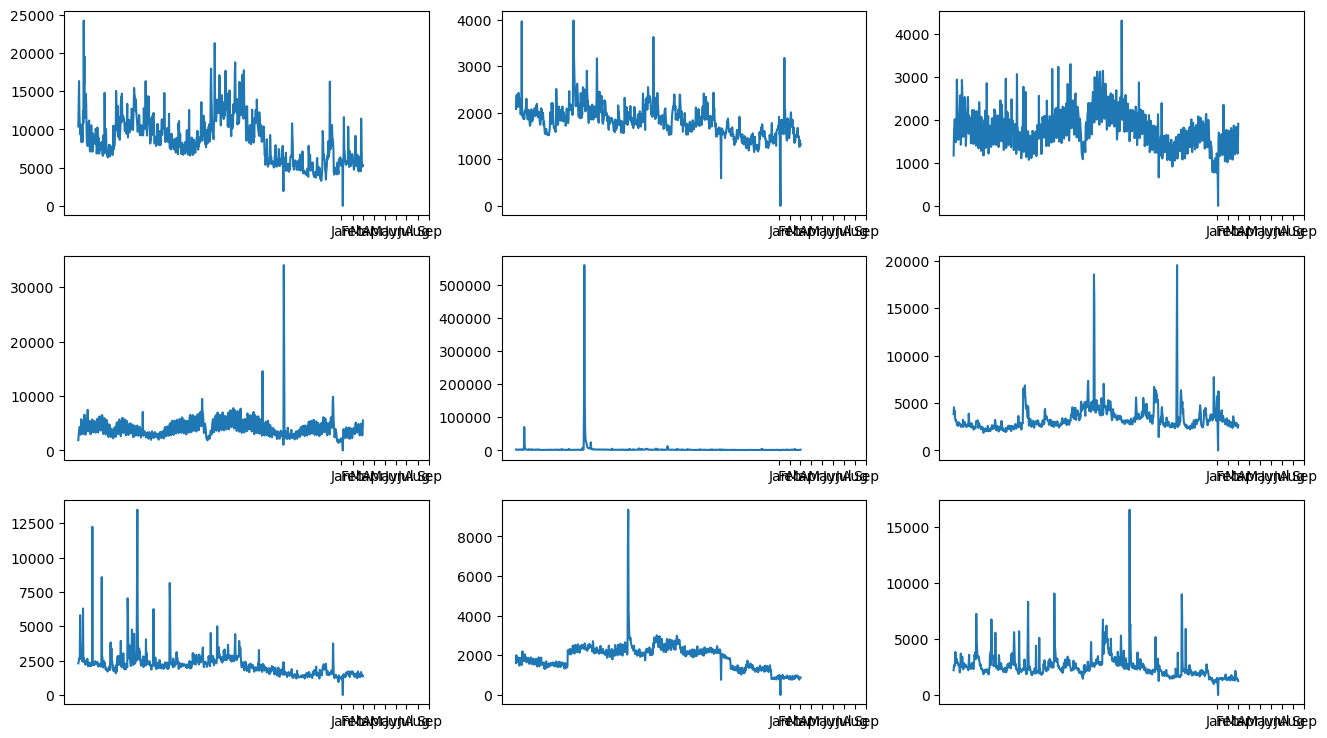

In [45]:
fig = plt.figure(figsize=(16, 9))
for idx, entry in enumerate(islice(dataset.train, 9)):
    ax = plt.subplot(3, 3, idx + 1)
    t = pd.date_range(
        start=entry["start"].to_timestamp(),
        periods=len(entry["target"]),
        freq=entry["start"].freq,
    )
    plt.plot(t, entry["target"])
    plt.xticks(pd.date_range(start="2014-01-01 00:00", periods=9, freq="1MS"))
    ax.xaxis.set_major_formatter(date_formater)

In [21]:
entry["target"].shape, entry["start"], entry["feat_static_cat"]

((5833,), Period('2014-01-01 00:00', 'h'), array([8], dtype=int32))

In [18]:
from gluonts.dataset.field_names import FieldName
from gluonts.transform import (
    AddObservedValuesIndicator,
    InstanceSplitter,
    ExpectedNumInstanceSampler,
    TestSplitSampler,
    Transformation,
    Chain,
    InstanceSampler,
    SelectFields,
)

from gluonts.dataset.loader import TrainDataLoader, InferenceDataLoader, ValidationDataLoader
from gluonts.itertools import Cached


In [20]:
from gluonts.transform import  SimpleTransformation,ValidationSplitSampler, TestSplitSampler
import numpy as np

class NumpyMeanScaler(SimpleTransformation):
    """
    GluonTS transform that implements mean scaling using numpy.
    """
    def __init__(
        self,
        dim=-1,
        keepdim=False,
        default_scale=None,
        minimum_scale=1e-10,
        field_name="target",
        ):
        self.dim = dim
        self.keepdim = keepdim
        self.default_scale = default_scale
        self.minimum_scale = minimum_scale
        self.field_name = field_name
        
    def transform(self, data: dict) -> dict:
        # Get the target data
        target = data[self.field_name]
        
        # Create observed indicator (assuming no missing values, modify if needed)
        observed_indicator = np.ones_like(target)
        
        # Compute scale factors
        ts_sum = np.sum(np.abs(target * observed_indicator), axis=self.dim, keepdims=True)
        num_observed = np.sum(observed_indicator, axis=self.dim, keepdims=True)
        scale = ts_sum / np.clip(num_observed, a_min=1, a_max=None)
        
        # Handle default scale
        if self.default_scale is None:
            batch_sum = np.sum(ts_sum, axis=0)
            batch_observations = np.clip(np.sum(num_observed, axis=0), a_min=1, a_max=None)
            default_scale = np.squeeze(batch_sum / batch_observations)
        else:
            default_scale = self.default_scale * np.ones_like(scale)
        
        # Apply default scale where there are no observations
        scale = np.where(num_observed > 0, scale, default_scale)
        
        # Ensure minimum scale
        scale = np.clip(scale, a_min=self.minimum_scale, a_max=None)
        
        # Scale the data
        scaled_data = target / scale
        
        if not self.keepdim:
            scale = np.squeeze(scale, axis=self.dim)
            
        # Store scaled data and scale factors in the dictionary
        data[self.field_name] = scaled_data
        data['scale'] = scale
        data['loc'] = np.zeros_like(scale)
        
        return data

In [21]:
from typing import List
import jax.numpy as jnp
from functools import partial
import numpy as np

def stack(data, device=None):
    if isinstance(data[0], (np.ndarray, jnp.ndarray)):
        return jnp.array(data)
    elif isinstance(data[0], (list, tuple)):
        return list(stack(t) for t in zip(*data))
    return data

def batchify(data: List[dict]) -> dict:
    return {
        key: stack(data=[item[key] for item in data])
        for key in data[0].keys()
    }

In [22]:
prediction_length = dataset.metadata.prediction_length
context_length = 2 * prediction_length
TOTAL_LEN = dataset_train[0]['target'].shape[1]
VAL_SIZE = TOTAL_LEN - prediction_length - context_length
VAL_START = TOTAL_LEN - VAL_SIZE


mask_unobserved = AddObservedValuesIndicator(
    target_field=FieldName.TARGET,
    output_field=FieldName.OBSERVED_VALUES,
)


training_splitter = InstanceSplitter(
    target_field=FieldName.TARGET,
    is_pad_field=FieldName.IS_PAD,
    start_field=FieldName.START,
    forecast_start_field=FieldName.FORECAST_START,
    instance_sampler=ExpectedNumInstanceSampler(
        num_instances=1,
        min_future=prediction_length,
        max_future=VAL_START
    ),
    past_length=context_length,
    future_length=prediction_length,
    time_series_fields=[FieldName.FEAT_TIME]
)

# Validation splitter - uses data from validation start onwards
validation_splitter = InstanceSplitter(
    target_field=FieldName.TARGET,
    is_pad_field=FieldName.IS_PAD,
    start_field=FieldName.START,
    forecast_start_field=FieldName.FORECAST_START,
    instance_sampler=ValidationSplitSampler(
        min_past=VAL_START,
        min_future=prediction_length),
    past_length=context_length,
    future_length=prediction_length,
    time_series_fields=[FieldName.FEAT_TIME]
)

In [23]:
batch_size = 5

data_loader = TrainDataLoader(
    Cached(dataset_train),
    batch_size=batch_size,
    transform=Chain([NumpyMeanScaler(field_name=FieldName.TARGET), training_splitter]),
    stack_fn=batchify,
)

val_data_loader = ValidationDataLoader(
    Cached(dataset_train),
    batch_size=batch_size,
    transform=Chain([NumpyMeanScaler(field_name=FieldName.TARGET), validation_splitter]),
    stack_fn=batchify,
)

In [27]:
test_splitter = InstanceSplitter(
    target_field=FieldName.TARGET,
    is_pad_field=FieldName.IS_PAD,
    start_field=FieldName.START,
    forecast_start_field=FieldName.FORECAST_START,
    instance_sampler=TestSplitSampler(),
    past_length=context_length,
    future_length=prediction_length,
    time_series_fields=[FieldName.FEAT_TIME]
)

test_data_loader = InferenceDataLoader(
    dataset=dataset_test,
    transform=Chain([NumpyMeanScaler(field_name=FieldName.TARGET), test_splitter]),
    batch_size=1,
    stack_fn=batchify,
)

test_batches = list(test_data_loader)
print(len(test_batches))
print(test_batches[0].keys())
for batch in test_batches:
    print(batch['past_target'].shape)
    print(batch['past_time_feat'].shape)


7
dict_keys(['start', 'feat_static_cat', 'scale', 'loc', 'past_time_feat', 'future_time_feat', 'past_target', 'future_target', 'past_is_pad', 'forecast_start'])
(1, 48, 370)
(1, 48, 6)
(1, 48, 370)
(1, 48, 6)
(1, 48, 370)
(1, 48, 6)
(1, 48, 370)
(1, 48, 6)
(1, 48, 370)
(1, 48, 6)
(1, 48, 370)
(1, 48, 6)
(1, 48, 370)
(1, 48, 6)


In [319]:
# Get validation length
val_batches = list(val_data_loader)
print(f"Number of validation batches: {len(val_batches)}")
print(f"Number of validation samples: {sum(batch['future_target'].shape[0] for batch in val_batches)}")

Number of validation batches: 1
Number of validation samples: 1


In [320]:
for batch in val_data_loader:
    print(batch['forecast_start'])

[Period('2014-08-31 01:00', 'h')]


In [321]:
batch["past_target"].shape, batch["future_target"].shape

((1, 48, 370), (1, 24, 370))

In [284]:
batch = next(iter(val_data_loader))
print(batch.keys())

dict_keys(['start', 'feat_static_cat', 'scale', 'loc', 'past_time_feat', 'future_time_feat', 'past_target', 'future_target', 'past_is_pad', 'forecast_start'])


In [57]:
batch["past_target"].shape, batch["future_target"].shape

((2, 48, 370), (2, 24, 370))

In [18]:
start = batch["start"]
feat_static_cat = batch["feat_static_cat"]
#item_id = batch["item_id"]
past_observed_values = batch["past_observed_values"]
future_observed_values = batch["future_observed_values"]
past_is_pad = batch["past_is_pad"]
past_target = batch["past_target"]
future_target = batch["future_target"]
forecast_start = batch["forecast_start"]

In [19]:
print(f"past_target.shape = {past_target.shape}")
print(f"future_target.shape = {future_target.shape}")


print(f"start: {start}")
print(f"feat_static_cat: {feat_static_cat}") 
#print(f"item_id: {item_id}")
print(f"forecast_start: {forecast_start}")


past_target.shape = (8, 48, 370)
future_target.shape = (8, 24, 370)
start: [Period('2014-01-01 00:00', 'h'), Period('2014-01-01 00:00', 'h'), Period('2014-01-01 00:00', 'h'), Period('2014-01-01 00:00', 'h'), Period('2014-01-01 00:00', 'h'), Period('2014-01-01 00:00', 'h'), Period('2014-01-01 00:00', 'h'), Period('2014-01-01 00:00', 'h')]
feat_static_cat: [[0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]]
forecast_start: [Period('2014-08-09 14:00', 'h'), Period('2014-04-04 14:00', 'h'), Period('2014-01-28 22:00', 'h'), Period('2014-04-02 03:00', 'h'), Period('2014-07-22 06:00', 'h'), Period('2014-06-05 09:00', 'h'), Period('2014-04-11 20:00', 'h'), Period('2014-05-28 15:00', 'h')]


In [43]:
from gluonts.dataset.split import split
from gluonts.dataset.util import period_index
from typing import Optional, Tuple, Iterator
from gluonts.dataset.common import DataEntry, Dataset

window_length = prediction_length 
_, test_template = split(dataset_test, offset=-window_length)
test_data_ = test_template.generate_instances(window_length)
dataset = test_data_.input 


prediction_splitter = InstanceSplitter(
    target_field=FieldName.TARGET,
    is_pad_field=FieldName.IS_PAD,
    start_field=FieldName.START,
    forecast_start_field=FieldName.FORECAST_START,
    instance_sampler=TestSplitSampler(),
    past_length=context_length,
    future_length=prediction_length,
    time_series_fields=[FieldName.FEAT_TIME],
) 

input_names = ["past_target"]
required_fields = ["forecast_start", "past_time_feat", "future_time_feat"]

dataloader = InferenceDataLoader(dataset=dataset_test, 
                                transform=prediction_splitter + SelectFields(input_names + required_fields, allow_missing=True),
                                batch_size=32,
                                stack_fn=batchify)



#predictor

def _to_dataframe(input_label: Tuple[DataEntry, DataEntry]) -> pd.DataFrame:
    """
    Turn a pair of consecutive (in time) data entries into a dataframe.
    """
    start = input_label[0][FieldName.START]
    targets = [entry[FieldName.TARGET] for entry in input_label]
    full_target = np.concatenate(targets, axis=-1)
    index = period_index(
        {FieldName.START: start, FieldName.TARGET: full_target}
    )
    return pd.DataFrame(full_target.transpose(), index=index)

def forecast(dataloader, model, input_names, n_samples):
    forecast_it = model.evaluate(dataloader, n_samples) # replace with the function that evaluates the model and returns an iterator of forecasts
    return forecast_it, map(_to_dataframe, test_data),


    





In [2]:
for batch in test_data_:
    for b in batch:
        print(b['target'].shape)
    print("-------")

NameError: name 'test_data_' is not defined

In [81]:
batch_test = next(iter(dataloader))

In [41]:
def make_evaluation_predictions(dataset, prediction_length, num_samples, model):
    window_length = prediction_length 
    _, test_template = split(dataset_test, offset=-window_length)
    test_data = test_template.generate_instances(window_length)
    dataset = test_data.input 
    
    forecast_it, ts_it = forecast(dataloader, model, input_names, num_samples)
    return list(forecast_it), list(ts_it)

In [37]:
from gluonts.model.predictor import OutputTransform, RepresentablePredictor
from gluonts.model.forecast_generator import (
    ForecastGenerator,
    SampleForecastGenerator,
    to_numpy,
)
from gluonts.core.component import validated
from typing import Iterator, List, Optional, Union
from gluonts.model.forecast import Forecast
from gluonts.itertools import select


In [52]:
import flax.nnx as nnx
import jax
import jax.random as jrandom

class JaxPredictor(RepresentablePredictor):
    @validated()
    def __init__(
        self,
        config,
        input_names: List[str],
        prediction_net: nnx.Module,
        batch_size: int,
        prediction_length: int,
        input_transform: Transformation,
        forecast_generator: ForecastGenerator = SampleForecastGenerator(),
        output_transform: Optional[OutputTransform] = None,
        lead_time: int = 0,
    ) -> None:
        super().__init__(prediction_length, lead_time=lead_time)
        self.config = config
        self.input_names = input_names
        self.batch_size = batch_size
        self.input_transform = input_transform
        self.forecast_generator = forecast_generator
        self.output_transform = output_transform
        self.prediction_net = prediction_net
        self.required_fields = ["forecast_start", "past_time_feat", "future_time_feat"]

    @property
    def network(self):
        return self.prediction_net
    
    def predict(self, dataset: Dataset, num_samples: Optional[int] = None) -> Iterator[Forecast]:
        inference_data_loader = InferenceDataLoader(
            dataset,
            transform=self.input_transform
            + SelectFields(
                self.input_names + self.required_fields, allow_missing=True
            ),
            batch_size=self.batch_size,
            stack_fn=lambda data: batchify(data),
        )

        keys = jrandom.split(self.rngs(), self.config.inference.mcmc_samples)
        evaluator = FlowEvaluator(self.prediction_net, nfe=self.config.inference.nfe)

        for batch in inference_data_loader:
            history = jnp.array(batch["past_target"])
            future_covariates = jnp.array(batch["future_time_feat"])
            past_covariates = jnp.array(batch["past_time_feat"])
            covariates = jnp.concatenate([past_covariates, future_covariates], axis=1)
            print(history.shape, covariates.shape)
            print(batch["forecast_start"])
            predictions = jax.vmap(jax.vmap(evaluator.predict_trajectory, in_axes=(0,None,None,None)),in_axes=(None,0,0,None))(keys, history, covariates, self.prediction_length)
            #Convert predictions to an iterator of forecasts
            





In [53]:
import jax
rngs = nnx.Rngs(0)
model = nnx.Linear(1, 3, rngs=rngs)
predictor = JaxPredictor(input_names=input_names,
                         prediction_net=model,
                         batch_size=32,
                         prediction_length=prediction_length,
                         input_transform=prediction_splitter,
                         forecast_generator=SampleForecastGenerator(),
                         output_transform=None,
                         lead_time=0)

In [54]:
predictor.predict(test_data_.input)

(7, 48, 370) (7, 72, 6)
[Period('2014-09-01 01:00', 'h'), Period('2014-09-02 01:00', 'h'), Period('2014-09-03 01:00', 'h'), Period('2014-09-04 01:00', 'h'), Period('2014-09-05 01:00', 'h'), Period('2014-09-06 01:00', 'h'), Period('2014-09-07 01:00', 'h')]


In [ ]:
class FlowPredictor(nnx.Module):
    """ Flow Predictor Module.

    Args:
        model: a Flax module that predicts the flow.
        config: a configuration object.
    """

    def __init__(self,
                model: nnx.Module,
                config: dict):
            self.model = model
            self.config = config

    
    def __call__(self, past_target, past_time_feat, future_time_feat, forecast_start):
        def vf(t, x, args):
            history, covariates = args
            return self.model(x, history, covariates, t)
        
        term = ODETerm(vf)
        solver = Tsit5()
        dt = 1/self.nfe

        predictions = []
        for _ in range(n_prediction_steps):
            x0 = jrandom.normal(key, shape=(history.shape[-1],))
            x_next = dfx.diffeqsolve(term, solver, 0., 1., dt, x0, args=(history, covariates), saveat=dfx.SaveAt(t1=True)).ys
            predictions.append(x_next) 
            history = jnp.concatenate([history, x_next], axis=0)
        return jnp.vstack(predictions)
          
          


